In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI 
from typing import TypedDict
from dotenv import load_dotenv

In [25]:
load_dotenv()

True

In [26]:
model = ChatOpenAI(model="gpt-6-luna")

In [27]:
class BlogState(TypedDict):
    title: str
    outline: str
    content: str

In [28]:
def create_outline(state: BlogState) -> BlogState:
    title = state["title"]

    prompt = f"Generate an outline for a blog on the topic: {title}"

    outline = model.invoke(prompt).content

    state["outline"] = outline
    return state

                     

In [29]:
def create_blog(state: BlogState) -> BlogState:
    title = state["title"]
    outline = state["outline"]

    prompt = f"Generate blog for the topic: {title} with the following outline: {outline}"

    content = model.invoke(prompt).content

    state["content"] = content
    return state

In [30]:
graph = StateGraph(BlogState)

#nodes
graph.add_node("create_outline",create_outline)
graph.add_node("create_blog", create_blog)

graph.add_edge(START, "create_outline")
graph.add_edge("create_outline", "create_blog")
graph.add_edge("create_blog", END)

In [31]:
workflow = graph.compile()

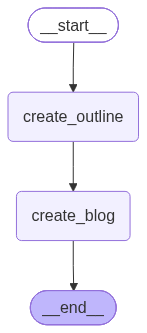

In [32]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [33]:
initial_state = {"title": "Rise of AI"}

final_state= workflow.invoke(initial_state)

In [34]:
final_state

{'title': 'Rise of AI',
 'outline': '# Blog Outline: The Rise of AI\n\n## 1. Introduction\n- What artificial intelligence (AI) means\n- Why AI has become a major topic in recent years\n- A brief look at how AI is changing everyday life\n\n## 2. A Brief History of AI\n- Early ideas and research\n- Key milestones in AI development\n- The shift from rule-based systems to machine learning and generative AI\n\n## 3. What’s Driving AI’s Growth?\n- More data and greater computing power\n- Advances in algorithms and machine learning\n- Investment from businesses and governments\n- The spread of AI tools into consumer products\n\n## 4. How AI Is Being Used Today\n- Healthcare and medical research\n- Education and personalized learning\n- Business, customer service, and productivity\n- Transportation and logistics\n- Creative work, including writing, art, and music\n- Everyday applications such as search, recommendations, and voice assistants\n\n## 5. Potential Benefits of AI\n- Automating repet

In [35]:
print(final_state["outline"])

# Blog Outline: The Rise of AI

## 1. Introduction
- What artificial intelligence (AI) means
- Why AI has become a major topic in recent years
- A brief look at how AI is changing everyday life

## 2. A Brief History of AI
- Early ideas and research
- Key milestones in AI development
- The shift from rule-based systems to machine learning and generative AI

## 3. What’s Driving AI’s Growth?
- More data and greater computing power
- Advances in algorithms and machine learning
- Investment from businesses and governments
- The spread of AI tools into consumer products

## 4. How AI Is Being Used Today
- Healthcare and medical research
- Education and personalized learning
- Business, customer service, and productivity
- Transportation and logistics
- Creative work, including writing, art, and music
- Everyday applications such as search, recommendations, and voice assistants

## 5. Potential Benefits of AI
- Automating repetitive tasks
- Supporting faster analysis and decision-making
- I

In [36]:
print(final_state["content"])

# The Rise of AI: How Artificial Intelligence Is Changing Our World

Artificial intelligence has moved from science fiction into daily life. It helps people find information, recommends what to watch, supports doctors as they analyze medical images, and powers tools that can write, summarize, or create images. As these technologies become more capable and widely available, AI is reshaping how we work, learn, and make decisions.

But what does AI actually mean, why is it growing so quickly, and what might its rise mean for society?

## What Is Artificial Intelligence?

Artificial intelligence, or AI, is a broad term for computer systems designed to perform tasks that typically require human abilities. These may include recognizing patterns, understanding language, making predictions, or generating new content.

AI does not necessarily think or understand the world as a person does. Many systems identify patterns in data and use them to produce a response or prediction. The results can b